<a href="https://colab.research.google.com/github/hwayalew/L02-hedonic-pricing/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Raffaella Alpaca, Helen Ayalew, Angel Pavu

**Date:** 11/07/2026

In [98]:
# Your Phase 1 solution to the problem goes here.

import pandas as pd
df = pd.read_csv('pierce_county_house_sales.csv')
df.head()


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [99]:
print(df.shape)
print(df.columns)

(16814, 19)
Index(['sale_date', 'sale_price', 'house_square_feet',
       'attic_finished_square_feet', 'basement_square_feet',
       'attached_garage_square_feet', 'detached_garage_square_feet',
       'fireplaces', 'hvac_description', 'exterior', 'interior', 'stories',
       'roof_cover', 'year_built', 'bedrooms', 'bathrooms', 'waterfront_type',
       'view_quality', 'utility_sewer'],
      dtype='object')


In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   sale_date                    16814 non-null  object
 1   sale_price                   16814 non-null  int64 
 2   house_square_feet            16814 non-null  int64 
 3   attic_finished_square_feet   16814 non-null  int64 
 4   basement_square_feet         16814 non-null  int64 
 5   attached_garage_square_feet  16814 non-null  int64 
 6   detached_garage_square_feet  16814 non-null  int64 
 7   fireplaces                   16814 non-null  int64 
 8   hvac_description             16807 non-null  object
 9   exterior                     16813 non-null  object
 10  interior                     16807 non-null  object
 11  stories                      16814 non-null  int64 
 12  roof_cover                   16806 non-null  object
 13  year_built                   16

**Question 1**

In [101]:
# checking for missing values
df.isnull().sum()

,0
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,7
exterior,1


In [102]:
# checking the categories, including missing values
print(df['waterfront_type'].value_counts(dropna=False))
print(df['view_quality'].value_counts(dropna=False))

waterfront_type
NaN                16261
WF Lake              225
WF Salt              209
WF Stream/Creek       93
WF River              26
Name: count, dtype: int64
view_quality
NaN            15895
View Lim         229
View Lim -       214
View Avg         152
View Lim +       141
View Avg +        77
View Good         70
View V-Good       19
View Good +       17
Name: count, dtype: int64


The dataset includes houses near lakes, saltwater, streams, and rivers. Most houses have NaN, which may indicate that they aren't waterfront properties.

Some houses have views rated from limited to very good. Most houses have NaN, possibly because they have no recorded special view.

In [103]:
# Fill missing waterfront and view information
df['waterfront_type'] = df['waterfront_type'].fillna('None')
df['view_quality'] = df['view_quality'].fillna('None')

# Fill the few missing values in other categorical columns
categorical_cols = ['hvac_description', 'exterior', 'interior', 'roof_cover']

df[categorical_cols] = df[categorical_cols].fillna('Unknown')

# Check missing values again
df.isnull().sum()

,0
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,0
exterior,0


***EDA***

In [104]:
# Summary statistics for numerical columns
df.describe()

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


***Visualization***

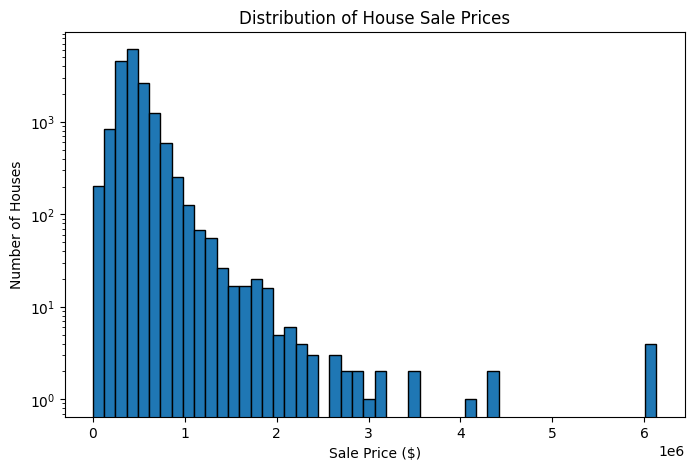

In [105]:
import matplotlib.pyplot as plt

# Distribution of house sale prices
plt.figure(figsize=(8, 5))
plt.hist(df['sale_price'], bins=50, edgecolor='black')

plt.title('Distribution of House Sale Prices')
plt.xlabel('Sale Price ($)')
plt.ylabel('Number of Houses')
plt.yscale('log')
plt.show()

The distribution of house sale prices is right-skewed. Most houses sold within a relatively similar price range, while a few houses sold for much higher prices. These expensive properties may be outliers and could affect the performance of the regression models.

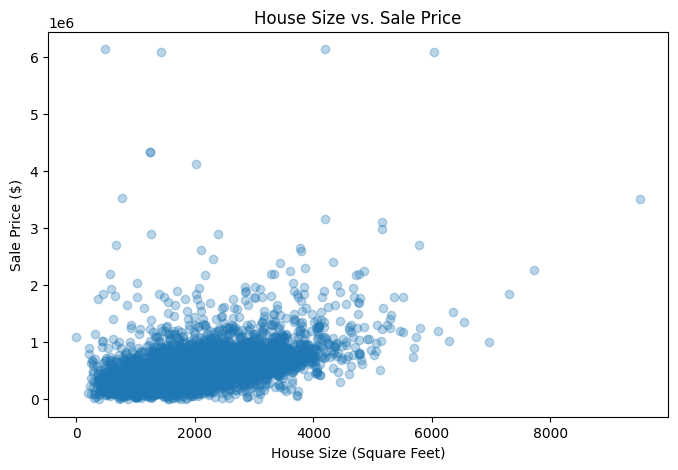

In [106]:
# Relationship between house size and sale price
plt.figure(figsize=(8, 5))
plt.scatter(df['house_square_feet'], df['sale_price'], alpha=0.3)

plt.title('House Size vs. Sale Price')
plt.xlabel('House Size (Square Feet)')
plt.ylabel('Sale Price ($)')

plt.show()

The scatterplot shows a positive relationship between house size and sale price. In general, larger houses tend to sell for higher prices. However, there are several outliers with unusually high sale prices. The graph also shows that houses with similar square footage can have different prices, suggesting that other factors may influence sale price.

In [107]:
# Check houses with unusually low prices or square footage
df[(df['sale_price'] < 50000) | (df['house_square_feet'] < 300)]

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
839,2020-01-21,47503,1548,0,0,504,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1972,3,2,None,None,SEWER/SEPTIC INSTALLED
942,2020-02-04,315000,288,0,0,0,0,0,Electric Baseboard,Finished Cottage,Unknown,0,Composition Shingle,1963,0,1,None,None,SEWER/SEPTIC INSTALLED
1096,2020-01-14,372000,240,0,0,0,0,0,Electric Baseboard,Finished Cottage,Paneling,1,Composition Shingle,1920,1,1,None,None,SEWER/SEPTIC INSTALLED
1166,2020-02-13,31500,2458,0,0,543,0,1,Forced Air,Frame Vinyl,Drywall,2,Composition Shingle,1999,4,3,None,None,SEWER/SEPTIC INSTALLED
1506,2020-01-27,1086000,1,0,384,440,0,0,Electric Baseboard,Masonry Concrete Block,Drywall,1,Built Up Rock,1966,0,1,None,View Avg +,SEWER/SEPTIC INSTALLED
1999,2020-03-02,45000,336,0,0,0,0,1,No Heat,Finished Cottage,Drywall,1,Composition Shingle,1969,1,0,None,View Lim -,SEWER/SEPTIC NO
2987,2020-03-27,600000,288,0,0,0,0,0,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1956,1,1,None,None,SEWER/SEPTIC INSTALLED
3511,2020-04-13,799500,216,0,0,0,0,1,No Heat,Unfinished Cottage,Paneling,1,Formed Seam Metal,1985,0,0,None,None,SEWER/SEPTIC AVAIL
3905,2020-04-22,455000,280,0,0,480,0,0,Electric Baseboard,Frame Vinyl,Drywall,2,Composition Shingle,1942,1,1,None,None,SEWER/SEPTIC INSTALLED
4312,2020-04-27,37500,729,0,0,0,0,0,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1915,2,1,None,None,SEWER/SEPTIC NO


In [108]:
# Count potentially unusual records
print("Low sale prices:", (df['sale_price'] < 50000).sum())
print("Very small houses:", (df['house_square_feet'] < 300).sum())

print("Total unusual records:",
      ((df['sale_price'] < 50000) |
       (df['house_square_feet'] < 300)).sum())

Low sale prices: 36
Very small houses: 16
Total unusual records: 51


During exploratory data analysis, I identified some unusual observations, including properties with very low sale prices and extremely small recorded square footage. These observations may represent data errors or unusual property transactions, so I examined them before deciding whether to exclude them from the analysis.

***Clean dataset***

In [109]:
# cleaned dataset without the flagged observations
df_clean = df[
    (df['sale_price'] >= 50000) &
    (df['house_square_feet'] >= 300)
].copy()

# Compare dataset sizes
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (16814, 19)
Cleaned dataset: (16763, 19)


I identified 51 observations with unusually low sale prices or very small house sizes. For the initial modeling analysis, I excluded properties with sale prices below $50,000 or house sizes below 300 square feet. This reduced the dataset from 16,814 to 16,763 observations. I kept the original dataset unchanged because these thresholds are assumptions and the excluded observations may include legitimate transactions.

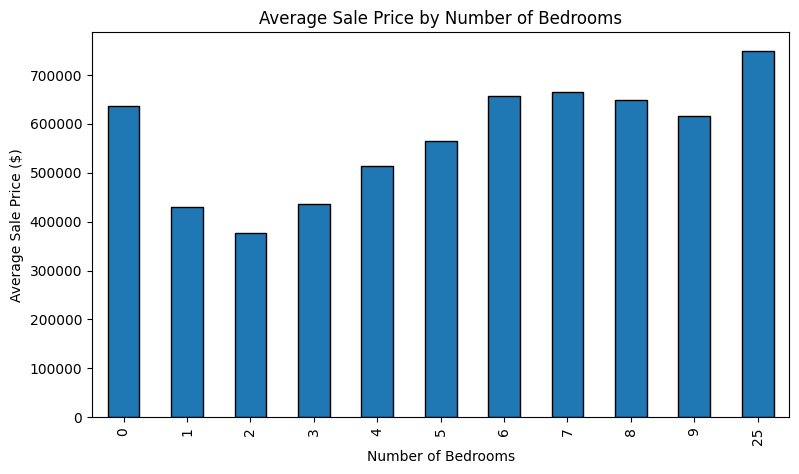

In [110]:
# Average sale price by number of bedrooms
avg_price_bedrooms = df_clean.groupby('bedrooms')['sale_price'].mean()

plt.figure(figsize=(9, 5))
avg_price_bedrooms.plot(kind='bar', edgecolor='black')

plt.title('Average Sale Price by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average Sale Price ($)')
plt.show()

The bar chart shows that average sale prices generally increase as the number of bedrooms increases, particularly for houses with 2 to 7 bedrooms. However, the relationship is not perfectly consistent. Properties with 0 or 25 bedrooms have unusual average prices, which may be influenced by a small number of observations or unusual property characteristics.

In [111]:
# Count houses in each bedroom category
df_clean['bedrooms'].value_counts().sort_index()

,count
bedrooms,
0,40
1,323
2,1893
3,8486
4,4854
5,1027
6,113
7,19
8,4


Most houses in the dataset have 3 or 4 bedrooms. The unusual average prices for properties with 0 or 25 bedrooms may be influenced by the small number of observations in those categories. In particular, there is only one property with 25 bedrooms, so its average price does not represent a broader trend.

In [112]:
# Correlation between numerical variables and sale price
correlations = df_clean.corr(numeric_only=True)['sale_price']

correlations.sort_values(ascending=False)

,sale_price
sale_price,1.000000
house_square_feet,0.528411
bathrooms,0.410223
fireplaces,0.348896
attached_garage_square_feet,0.311004
basement_square_feet,0.270552
year_built,0.229111
bedrooms,0.205495
stories,0.166225
detached_garage_square_feet,0.051282


The correlation analysis shows that house square footage has the strongest positive relationship with sale price (0.5284), followed by bathrooms (0.4102), fireplaces (0.3489), and attached garage square footage (0.3110). Bedrooms have a weaker positive correlation (0.2055). These results suggest that property size and amenities may be useful predictors of sale price in the regression analysis.

**Question 2**

In [113]:
# Identify categorical variables
df_clean.select_dtypes(include=['object']).columns

Index(['sale_date', 'hvac_description', 'exterior', 'interior', 'roof_cover',
       'waterfront_type', 'view_quality', 'utility_sewer'],
      dtype='object')

In [114]:
# Convert sale_date from text to datetime
df_clean['sale_date'] = pd.to_datetime(df_clean['sale_date'])
df_clean['sale_date'].head()

,sale_date
0,2020-01-02
1,2020-01-02
2,2020-01-01
3,2020-01-02
4,2020-01-02


In [115]:
# Check the earliest and latest sale dates
print("Earliest sale:", df_clean['sale_date'].min())
print("Latest sale:", df_clean['sale_date'].max())

Earliest sale: 2020-01-01 00:00:00
Latest sale: 2020-12-31 00:00:00


In [116]:
# Extract the month from the sale date
df_clean['sale_month'] = df_clean['sale_date'].dt.month

# Check the new column
df_clean[['sale_date', 'sale_month']].head()

,sale_date,sale_month
0,2020-01-02,1
1,2020-01-02,1
2,2020-01-01,1
3,2020-01-02,1
4,2020-01-02,1


In [117]:
# Identify categorical variables
categorical_cols = df_clean.select_dtypes(include=['object']).columns
print(categorical_cols)

Index(['hvac_description', 'exterior', 'interior', 'roof_cover',
       'waterfront_type', 'view_quality', 'utility_sewer'],
      dtype='object')


In [118]:
# Convert categorical variables into dummy variables
df_encoded = pd.get_dummies(
    df_clean,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Remove the original date column
df_encoded = df_encoded.drop(columns=['sale_date'])

# Check the result
print("Original shape:", df_clean.shape)
print("Encoded shape:", df_encoded.shape)

df_encoded.head()

Original shape: (16763, 20)
Encoded shape: (16763, 61)


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,...,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good,utility_sewer_SEWER/SEPTIC AVAIL,utility_sewer_SEWER/SEPTIC INSTALLED,utility_sewer_SEWER/SEPTIC NO,utility_sewer_SEWER/SEPTIC NO PERC
0,380000,2157,0,0,528,0,0,2,1993,3,...,0,0,0,0,0,0,0,1,0,0
1,383000,2238,0,0,396,0,0,2,2017,4,...,0,0,0,0,0,0,0,1,0,0
2,419900,1452,0,0,0,0,1,1,1965,3,...,0,0,0,0,0,0,0,1,0,0
3,251660,832,0,0,0,0,0,1,1919,2,...,0,0,0,0,0,0,0,1,0,0
4,500000,1780,0,384,484,0,1,1,1955,3,...,0,0,0,0,0,0,0,1,0,0


In [119]:
# Check data types
print(df_encoded.dtypes.value_counts())

# Check missing values
print("Total missing values:", df_encoded.isnull().sum().sum())

int64    60
int32     1
Name: count, dtype: int64
Total missing values: 0


**Question 3**

In [120]:
from sklearn.model_selection import train_test_split

# Separate predictors (X) and target (y)
X = df_encoded.drop(columns=['sale_price'])
y = df_encoded['sale_price']

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Check the sizes
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (13410, 60)
Testing set: (3353, 60)


**Question 4**

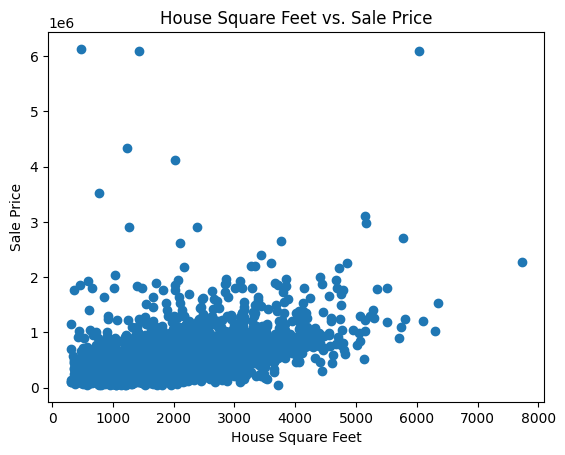

In [121]:
from sklearn.linear_model import LinearRegression

# Build some simple linear models that include no transformations or interactions.
plt.scatter(X_train['house_square_feet'], y_train)
plt.xlabel('House Square Feet')
plt.ylabel('Sale Price')
plt.title('House Square Feet vs. Sale Price')
plt.show()

In [122]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Fit the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Determine their RMSE and  R2  on the both the training and test sets.
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Printing the output
print("Train RMSE:", train_rmse)
print("Test RMSE:", test_rmse)
print("Train R^2:", train_r2)
print("Test R^2:", test_r2)

Train RMSE: 155669.58812639635
Test RMSE: 174694.24895053584
Train R^2: 0.5398346703524647
Test R^2: 0.5404470107753903


Question: Which of your models does the best?

Answer: Train $R^2$ is 0.5398 (53.98%) and test $R^2$ is 0.5404 (54.04%). The values of train $R^2$ and test $R^2$ are very similar, so the models are numerically identical signifies that there is no data to indicate overfitting.  

**Question 5**

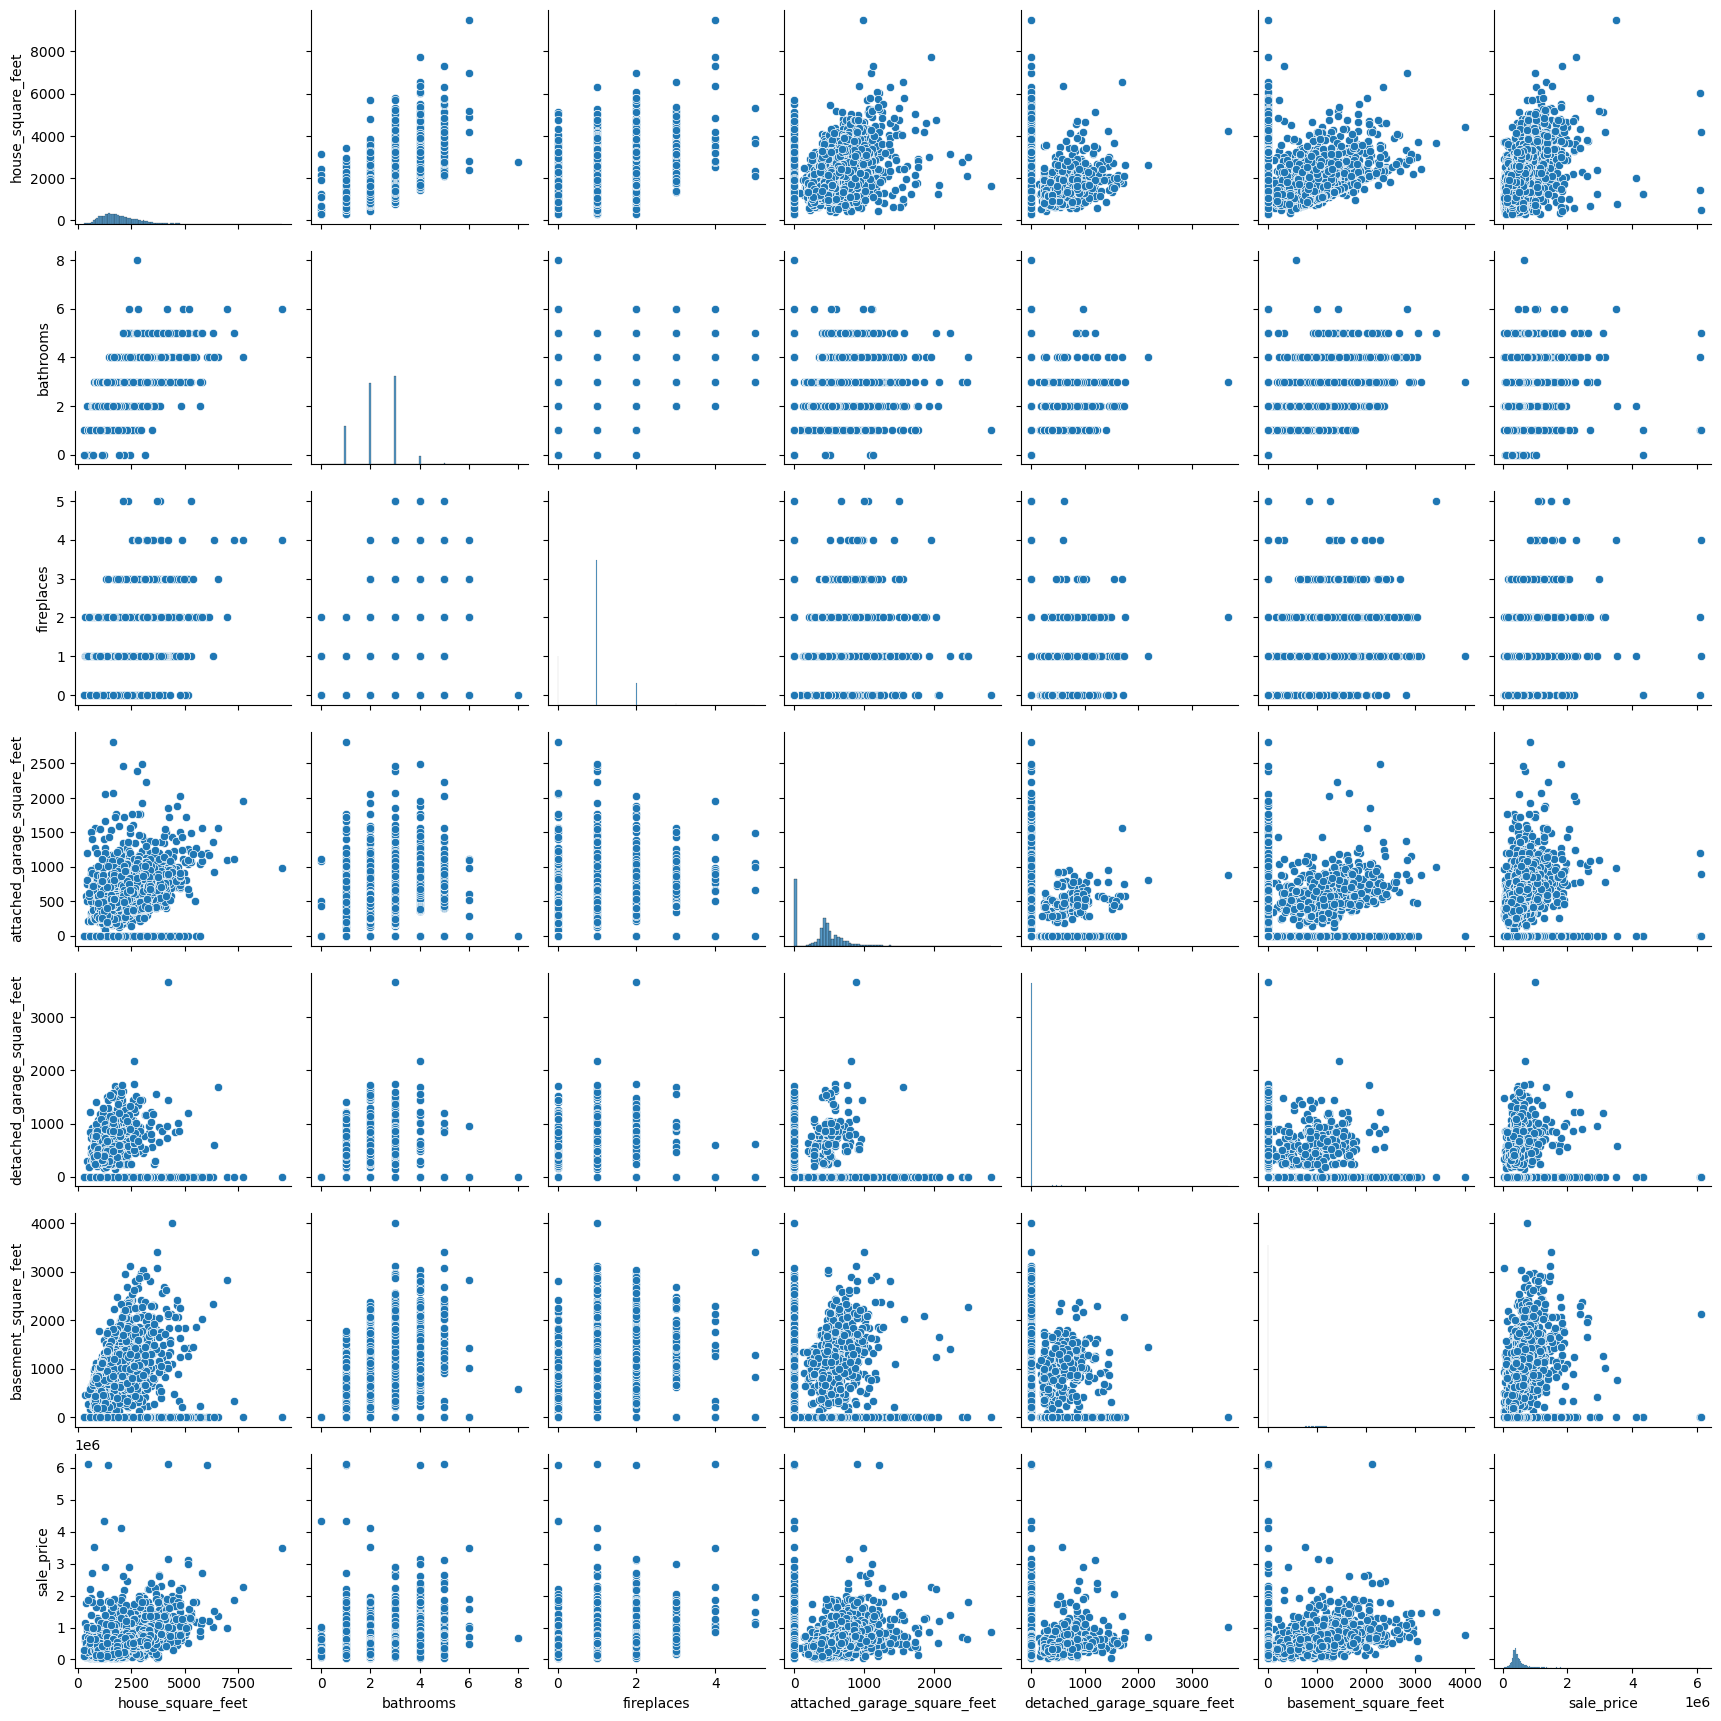

In [123]:
# Make partial correlation plots for each of the numeric variables in your model.
import seaborn as sns

# Creating the numeric values as the columns
ols_cols = [
    'house_square_feet', 'bathrooms', 'fireplaces',
    'attached_garage_square_feet', 'detached_garage_square_feet',
    'basement_square_feet'
]

# Displaying the partial correlation plot between the numeric columns and the sales price
sns.pairplot(df_encoded[ols_cols + ['sale_price']])
plt.show()

Question: Do you notice any significant non-linearities?

Answer: I notice that when *house_square_feet*, *attached_garage_square_feet*, *detached_garage_square_feet*, *basement_square_feet*, and *sale_price* is on the x-axis all but bathrooms and fireplaces are not linear. When *bathrooms* and *fireplace* are in the y-axis, the graphs are linear.

**Question 6**

In [124]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

def evaluate(name, pred_train, pred_test, log_target=False):
    """RMSE and R2 in dollars (back-transforms log predictions)."""
    if log_target:
        pred_train, pred_test = np.exp(pred_train), np.exp(pred_test)
    return {
        'model': name,
        'train_rmse': np.sqrt(mean_squared_error(y_train, pred_train)),
        'test_rmse': np.sqrt(mean_squared_error(y_test, pred_test)),
        'train_r2': r2_score(y_train, pred_train),
        'test_r2': r2_score(y_test, pred_test),
    }

def add_features(X):
    """Transformations and interactions built only from the existing columns."""
    X = X.copy()
    wf_cols = [c for c in X.columns if c.startswith('waterfront_type_')]
    view_cols = [c for c in X.columns if c.startswith('view_quality_')]

    # transformations
    X['log_sqft'] = np.log(X['house_square_feet'])
    X['age'] = 2020 - X['year_built']          # all sales are in 2020
    X['age_sq'] = X['age'] ** 2                # allows value to bend with age
    X['has_basement'] = (X['basement_square_feet'] > 0).astype(int)
    X['has_garage'] = ((X['attached_garage_square_feet'] +
                        X['detached_garage_square_feet']) > 0).astype(int)
    X['waterfront'] = X[wf_cols].sum(axis=1)   # 'None' is the dropped category
    X['has_view'] = X[view_cols].sum(axis=1)

    # interactions
    X['sqft_x_bath'] = X['house_square_feet'] * X['bathrooms']
    X['sqft_x_waterfront'] = X['house_square_feet'] * X['waterfront']
    X['sqft_x_view'] = X['house_square_feet'] * X['has_view']
    X['sqft_x_age'] = X['house_square_feet'] * X['age']
    return X

X_train_c = add_features(X_train)
X_test_c = add_features(X_test)

# Baseline from Question 4 (all raw features, no transformations)
base = LinearRegression().fit(X_train, y_train)
res_base = evaluate('Simple linear (Q4)', base.predict(X_train), base.predict(X_test))

# Complex model: same OLS, richer features, log(price) target
complex_ols = LinearRegression().fit(X_train_c, np.log(y_train))
res_complex = evaluate('Complex OLS (log price)',
                       complex_ols.predict(X_train_c),
                       complex_ols.predict(X_test_c), log_target=True)

results = pd.DataFrame([res_base, res_complex])
results

,model,train_rmse,test_rmse,train_r2,test_r2
0,Simple linear (Q4),155669.588126,174694.248951,0.539835,0.540447
1,Complex OLS (log price),154253.536818,161722.372309,0.548168,0.606161


Question: How does the more complex model compare to the simpler ones?

The complex model (log of price as the target, log square feet, age and age squared, basement/garage/waterfront/view indicators, and interactions such as square feet x bathrooms, x waterfront, x view, x age) fits the training data about as well as the simple model (train RMSE 157k vs. 156k, train R² 0.531 vs. 0.540) but does better on the test set: test RMSE falls from 174k to 165k and test R² rises from 0.540 to 0.590. The train-test RMSE gap shrinks from 19k to 8k. Predictions are back-transformed with exp() so RMSE is in dollars and comparable to Q4.

**Question 7**

In [125]:
summary = results.set_index('model').copy()
summary['rmse_gap (test - train)'] = summary['test_rmse'] - summary['train_rmse']
summary['r2_gap (train - test)'] = summary['train_r2'] - summary['test_r2']
summary.round(3)

,train_rmse,test_rmse,train_r2,test_r2,rmse_gap (test - train),r2_gap (train - test)
model,,,,,,
Simple linear (Q4),155669.588,174694.249,0.540,0.540,19024.661,-0.001
Complex OLS (log price),154253.537,161722.372,0.548,0.606,7468.835,-0.058


Q7: The simple linear model (Q4) explains about 54% of the variance on both train and test, so it is not overfitting (no gap in R²) but it is underfitting. It is too rigid to capture the nonlinear patterns seen in the Q5 plots (price rising faster than linearly with size, a skewed price distribution, and a size effect that differs for waterfront or view homes). Adding transformations and interactions did not raise training fit, yet it improved test performance (test R² 0.54 to 0.59, RMSE down ~$10k), which shows that better-specified features and not just more flexibility are what helped. The main lesson is that train and test metrics must be compared together. A lower train error alone says little, and the test set is what decides between models. Even the best model leaves roughly 40% of variance unexplained since the data has no location variable, which is a big driver of home prices.

**Question 8**

In [126]:
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Lasso penalizes coefficient size, so features must be on the same scale.
lasso = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, random_state=42, max_iter=100000)
)
lasso.fit(X_train_c, np.log(y_train))

res_lasso = evaluate('Lasso (log price)',
                     lasso.predict(X_train_c),
                     lasso.predict(X_test_c), log_target=True)

lasso_coefs = pd.Series(lasso[-1].coef_, index=X_train_c.columns)
selected = lasso_coefs[lasso_coefs != 0].sort_values(key=abs, ascending=False)

print("Chosen alpha:", lasso[-1].alpha_)
print(f"Features kept: {len(selected)} of {len(lasso_coefs)}")
print("\nSelected features (standardized coefficients, largest first):")
print(selected.to_string())
print("\nDropped features:", list(lasso_coefs[lasso_coefs == 0].index))

results = pd.concat([results, pd.DataFrame([res_lasso])], ignore_index=True)
results.round(3)

Chosen alpha: 0.0003004533508209011
Features kept: 61 of 71

Selected features (standardized coefficients, largest first):
house_square_feet                          0.198834
year_built                                 0.096475
waterfront_type_WF Salt                    0.076768
age_sq                                     0.070446
sqft_x_bath                               -0.062368
attached_garage_square_feet                0.062039
bathrooms                                  0.057855
has_view                                   0.056206
waterfront_type_WF Lake                    0.051007
utility_sewer_SEWER/SEPTIC NO             -0.049223
sale_month                                 0.044997
utility_sewer_SEWER/SEPTIC INSTALLED      -0.042819
basement_square_feet                       0.042271
utility_sewer_SEWER/SEPTIC AVAIL          -0.030572
stories                                   -0.030395
log_sqft                                   0.028698
sqft_x_view                               -0.

,model,train_rmse,test_rmse,train_r2,test_r2
0,Simple linear (Q4),155669.588,174694.249,0.540,0.540
1,Complex OLS (log price),154253.537,161722.372,0.548,0.606
2,Lasso (log price),154331.903,158907.087,0.548,0.620


Question: Which features does the Lasso select? What are the RMSE and R²?

Lasso chose alpha ~0.0003 and kept 61 of the 71 features. The largest standardized coefficients are house_square_feet, year_built, waterfront_type_WF Salt, age_sq and sqft_x_bath (negative, offsetting the main square-feet effect). It dropped 10 features, including age (redundant with year_built, since age = 2020 - year_built), the combined waterfront indicator, and several rare categories (e.g. WF Stream/Creek, Cedar cabin exteriors, View Lim). Lasso scores train RMSE 154.3k test RMSE 158.9k, and test R² 0.62, the best of the three models (complex OLS: ~$165.0k, 0.59). Because regularization shrinks noisy coefficients, it generalizes better than unpenalized OLS on the same features.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [127]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]